# Transición energética en Chile y América Latina — Análisis exploratorio

Este notebook explora el modelo de datos que generan los scripts de `src/` y produce los gráficos del README.

**Fuente:** Our World in Data, *Energy* y *CO2 and Greenhouse Gas Emissions* (CC BY 4.0).

**Antes de ejecutarlo:** corre desde la raíz del repositorio

```bash
python src/01_descargar_datos.py && python src/02_limpieza.py && python src/03_cargar_sql.py
```

In [1]:
from pathlib import Path
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = RAIZ / "data" / "processed"
IMG = RAIZ / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

dim_pais = pd.read_csv(PROC / "dim_pais.csv")
dim_fuente = pd.read_csv(PROC / "dim_fuente.csv")
fact_gen = pd.read_csv(PROC / "fact_generacion.csv")
fact_pa = pd.read_csv(PROC / "fact_pais_anio.csv")
con = sqlite3.connect(RAIZ / "data" / "transicion_energetica.db")

# Estilo sobrio: grilla tenue, sin bordes superiores/derechos
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlepad": 22, "axes.titlesize": 12, "axes.titlelocation": "left",
    "xtick.color": "#55554f", "ytick.color": "#55554f", "axes.labelcolor": "#55554f",
})
TINTA, TINTA_2, NEUTRO = "#1f1f1c", "#6b6b64", "#c9c8c0"
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
for nombre, df in {"dim_pais": dim_pais, "dim_fuente": dim_fuente, "fact_generacion": fact_gen, "fact_pais_anio": fact_pa}.items():
    print(f"{nombre:16s} {df.shape[0]:>7,} filas × {df.shape[1]} columnas")

dim_pais             214 filas × 6 columnas
dim_fuente             9 filas × 6 columnas
fact_generacion   48,483 filas × 4 columnas
fact_pais_anio     5,387 filas × 15 columnas


## 1. Revisión rápida de calidad
La limpieza completa y sus decisiones están en `outputs/reporte_calidad.md`. Aquí se vuelve a comprobar lo esencial.

In [2]:
controles = pd.Series({
    "Duplicados (país, año)": fact_pa.duplicated(["iso3", "anio"]).sum(),
    "Duplicados (país, año, fuente)": fact_gen.duplicated(["iso3", "anio", "fuente_id"]).sum(),
    "Generación negativa": (fact_gen.generacion_twh < 0).sum(),
    "% renovable fuera de [0, 100]": (~fact_pa.renovables_pct.between(0, 100)).sum(),
    "Países en hechos sin dimensión": (~fact_pa.iso3.isin(dim_pais.iso3)).sum(),
})
display(controles.to_frame("filas con problema"))

nulos = fact_pa.isna().mean().mul(100).round(1).sort_values(ascending=False)
display(nulos[nulos > 0].to_frame("% nulos"))

,filas con problema
"Duplicados (país, año)",0
"Duplicados (país, año, fuente)",0
Generación negativa,0
"% renovable fuera de [0, 100]",26
Países en hechos sin dimensión,0


,% nulos
pib_usd_ppa,29.6
co2_mt,3.4
co2_per_capita_t,3.4
fosil_pct,0.5
renovables_pct,0.5
nuclear_pct,0.5
intensidad_carbono_g_kwh,0.5


El PIB tiene más nulos porque OWID lo publica con varios años de rezago; no se usa en los cálculos principales. Los años con cobertura parcial se marcan con `anio_cobertura_completa = False`:

In [3]:
fact_pa.groupby("anio").agg(paises=("iso3", "nunique"), completo=("anio_cobertura_completa", "first")).tail(5)

,paises,completo
anio,,
2021,213,True
2022,213,True
2023,212,True
2024,196,True
2025,90,False


## 2. La matriz eléctrica de Chile (P1)

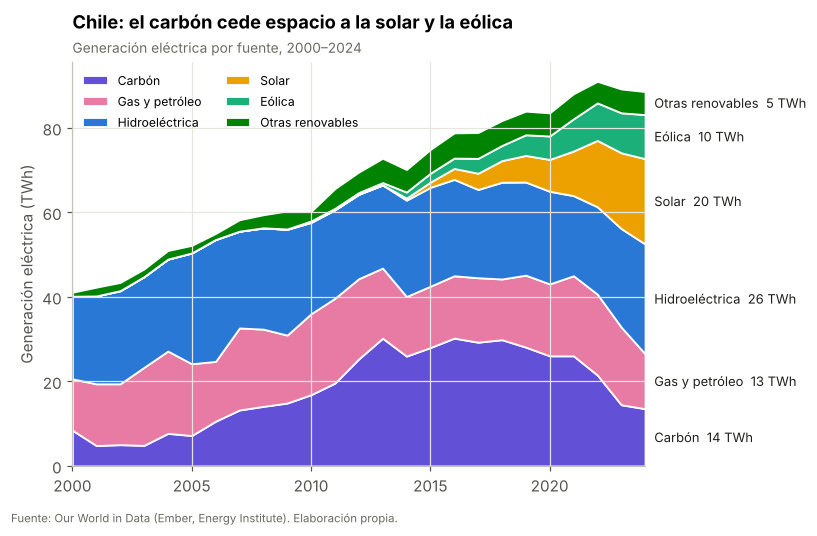

grupo_grafico,Carbón,Gas y petróleo,Hidroeléctrica,Solar,Eólica,Otras renovables
anio,,,,,,
2015,28.0,14.5,23.4,1.2,2.1,5.6
2024,13.6,13.0,26.0,20.2,10.4,5.4


In [4]:
mix = (fact_gen[(fact_gen.iso3 == "CHL") & (fact_gen.anio <= 2024)]
       .merge(dim_fuente, on="fuente_id")
       .pivot_table(index="anio", columns="grupo_grafico", values="generacion_twh", aggfunc="sum"))
orden = ["Carbón", "Gas y petróleo", "Hidroeléctrica", "Solar", "Eólica", "Otras renovables"]
mix = mix[[g for g in orden if g in mix.columns]]
colores = dim_fuente.drop_duplicates("grupo_grafico").set_index("grupo_grafico")["color_hex"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.stackplot(mix.index, mix.T.values, colors=[colores[g] for g in mix.columns],
             edgecolor="white", linewidth=1.2, labels=mix.columns)
# Etiquetas directas al final de cada banda
acum = mix.iloc[-1].cumsum() - mix.iloc[-1] / 2
for grupo, y in acum.items():
    ax.annotate(f"{grupo}  {mix.iloc[-1][grupo]:.0f} TWh", (mix.index[-1], y), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(2000, 2024)
ax.set_ylabel("Generación eléctrica (TWh)")
ax.set_title("Chile: el carbón cede espacio a la solar y la eólica")
ax.text(0, 1.015, "Generación eléctrica por fuente, 2000–2024", transform=ax.transAxes, va="bottom", color=TINTA_2, fontsize=9)
ax.legend(loc="upper left", frameon=False, fontsize=8, ncol=2)
fig.text(0.01, 0.0, "Fuente: Our World in Data (Ember, Energy Institute). Elaboración propia.", fontsize=7.5, color=TINTA_2)
fig.tight_layout(rect=(0, 0.02, 0.83, 1))
fig.savefig(IMG / "01_mix_chile.png", bbox_inches="tight")
plt.show()

mix.loc[[2015, 2024]].round(1)

## 3. Chile frente a la región y al mundo (P4)
Se reutiliza directamente la consulta SQL del repositorio, con promedios ponderados por generación.

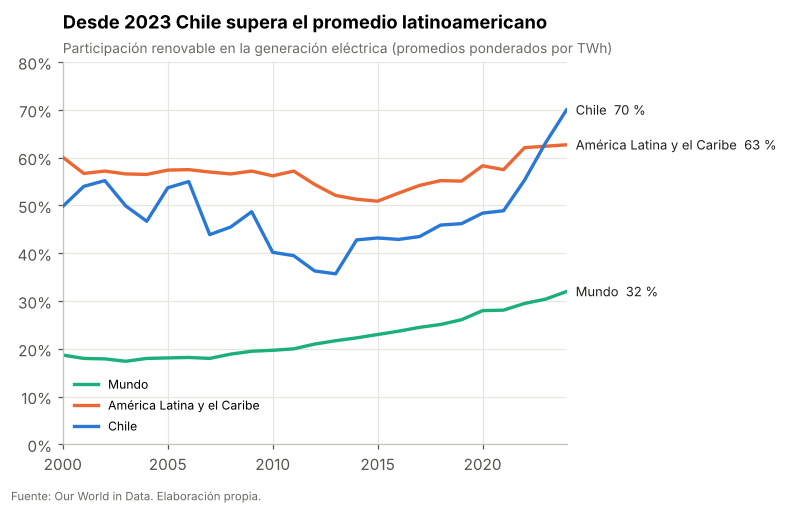

In [5]:
serie = pd.read_sql_query((RAIZ / "sql" / "04_chile_vs_latam_vs_mundo.sql").read_text(encoding="utf-8"), con)

fig, ax = plt.subplots(figsize=(9, 4.6))
for col, nombre, color, z in [("mundo_pct", "Mundo", AQUA, 2), ("latam_pct", "América Latina y el Caribe", NARANJA, 3), ("chile_pct", "Chile", AZUL, 4)]:
    ax.plot(serie.anio, serie[col], color=color, linewidth=2.2, label=nombre, zorder=z)
    ax.annotate(f"{nombre}  {serie[col].iloc[-1]:.0f} %", (serie.anio.iloc[-1], serie[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=TINTA)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 80); ax.set_xlim(2000, 2024)
ax.set_title("Desde 2023 Chile supera el promedio latinoamericano")
ax.text(0, 1.015, "Participación renovable en la generación eléctrica (promedios ponderados por TWh)", transform=ax.transAxes, va="bottom", color=TINTA_2, fontsize=9)
ax.legend(loc="lower left", frameon=False, fontsize=8)
fig.text(0.01, 0.0, "Fuente: Our World in Data. Elaboración propia.", fontsize=7.5, color=TINTA_2)
fig.tight_layout(rect=(0, 0.02, 0.8, 1))
fig.savefig(IMG / "02_chile_vs_latam_mundo.png", bbox_inches="tight")
plt.show()

## 4. Ranking latinoamericano (P2)

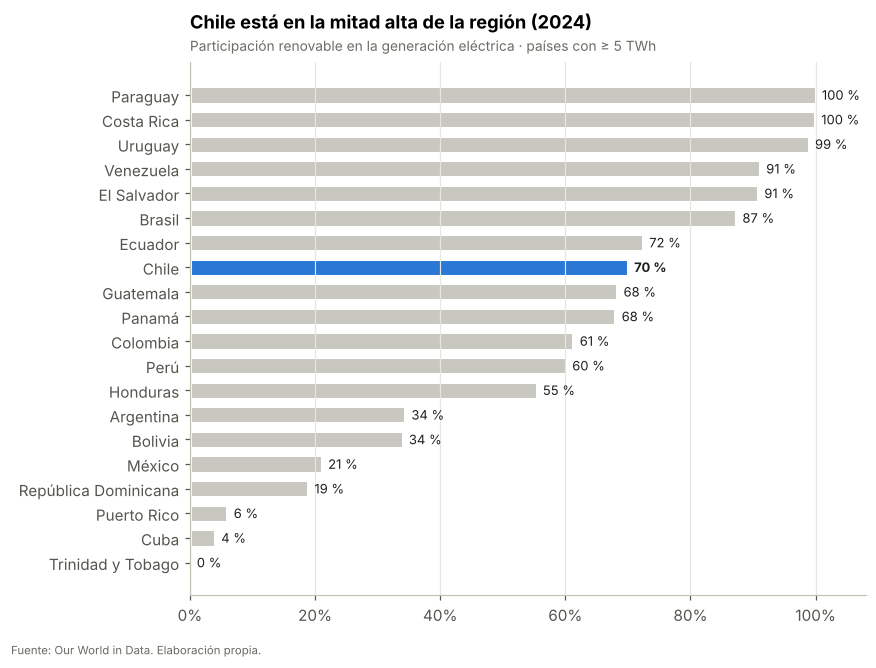

In [6]:
rank = pd.read_sql_query((RAIZ / "sql" / "02_ranking_latam_renovables.sql").read_text(encoding="utf-8"), con)
rank = rank[rank.generacion_twh >= 5].sort_values("renovables_pct")
anio_ref = int(rank.anio_referencia.iloc[0])

fig, ax = plt.subplots(figsize=(8, 6))
colores_barra = [AZUL if p == "Chile" else NEUTRO for p in rank.pais]
ax.barh(rank.pais, rank.renovables_pct, color=colores_barra, height=0.7, edgecolor="white", linewidth=2)
for y, (v, p) in enumerate(zip(rank.renovables_pct, rank.pais)):
    ax.text(v + 1, y, f"{v:.0f} %", va="center", fontsize=8.5, color=TINTA, fontweight="bold" if p == "Chile" else "normal")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 108); ax.grid(axis="y", visible=False)
ax.set_title(f"Chile está en la mitad alta de la región ({anio_ref})")
ax.text(0, 1.015, "Participación renovable en la generación eléctrica · países con ≥ 5 TWh", transform=ax.transAxes, va="bottom", color=TINTA_2, fontsize=9)
fig.text(0.01, 0.0, "Fuente: Our World in Data. Elaboración propia.", fontsize=7.5, color=TINTA_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(IMG / "03_ranking_latam.png", bbox_inches="tight")
plt.show()

## 5. Más renovables, electricidad más limpia (P7)

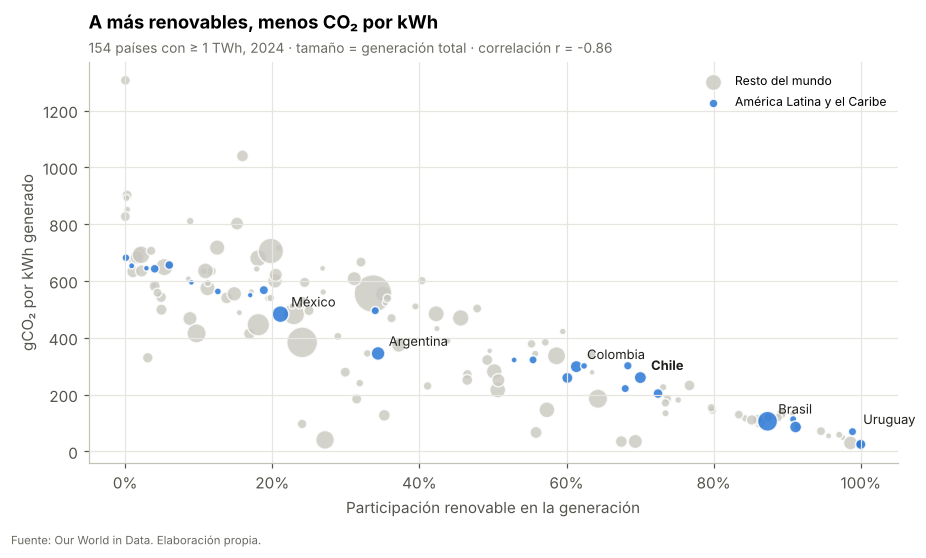

Correlación de Pearson: -0.86


In [7]:
ref = (fact_pa[(fact_pa.anio == anio_ref) & (fact_pa.generacion_twh >= 1)]
       .dropna(subset=["intensidad_carbono_g_kwh"]).merge(dim_pais, on="iso3"))
corr = ref[["renovables_pct", "intensidad_carbono_g_kwh"]].corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(8.5, 5))
resto, latam = ref[~ref.es_latam], ref[ref.es_latam]
tam = lambda s: (s ** 0.5) * 6 + 8
ax.scatter(resto.renovables_pct, resto.intensidad_carbono_g_kwh, s=tam(resto.generacion_twh), color=NEUTRO, alpha=0.8, edgecolor="white", linewidth=1, label="Resto del mundo")
ax.scatter(latam.renovables_pct, latam.intensidad_carbono_g_kwh, s=tam(latam.generacion_twh), color=AZUL, alpha=0.85, edgecolor="white", linewidth=1, label="América Latina y el Caribe")
for iso in ["CHL", "BRA", "MEX", "ARG", "URY", "COL"]:
    f = ref[ref.iso3 == iso].iloc[0]
    ax.annotate(f.pais, (f.renovables_pct, f.intensidad_carbono_g_kwh), xytext=(7, 5), textcoords="offset points", fontsize=8.5, color=TINTA,
                fontweight="bold" if iso == "CHL" else "normal")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Participación renovable en la generación"); ax.set_ylabel("gCO₂ por kWh generado")
ax.set_title("A más renovables, menos CO₂ por kWh")
ax.text(0, 1.015, f"{len(ref)} países con ≥ 1 TWh, {anio_ref} · tamaño = generación total · correlación r = {corr:.2f}", transform=ax.transAxes, va="bottom", color=TINTA_2, fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="upper right", markerscale=0.6)
fig.text(0.01, 0.0, "Fuente: Our World in Data. Elaboración propia.", fontsize=7.5, color=TINTA_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(IMG / "04_renovables_vs_intensidad.png", bbox_inches="tight")
plt.show()
print(f"Correlación de Pearson: {corr:.2f}")

## 6. Hallazgos

Los valores salen de las consultas de `sql/` (ver `outputs/resultados_consultas.md`).

1. **Chile pasó de 43 % a 70 % de generación renovable entre 2015 y 2024.** Es el mayor salto de solar + eólica en la región (+30 pp).
2. **El carbón bajó de 37 % a 15 %** de la generación chilena en el mismo periodo, una de las reducciones más grandes del mundo entre países con sistemas de ≥ 10 TWh.
3. **Desde 2023 Chile supera el promedio ponderado de América Latina y el Caribe** (63 % en 2024), que ya era alto por la hidroelectricidad de Brasil, Paraguay o Colombia.
4. **La relación renovables–emisiones es fuerte:** los países con 80–100 % renovable generan en promedio (ponderado por TWh) cerca de 7 veces menos CO₂ por kWh que los que están bajo 20 %.
5. **2025 es preliminar** (solo ~90 países informados). En Chile muestra una baja a 66 %, coherente con menor generación hidroeléctrica ese año; conviene confirmarlo cuando OWID complete la serie.

In [8]:
con.close()